# Statistical Analysis and Monte Carlo Estimation of Extreme Hourly Bike-Sharing Demand

Simulation and Modeling Lab  
**Course Code:** CSE 413  
**Dataset:** UCI Bike Sharing Dataset (`hour.csv`)  
**Tools:** Python, NumPy, pandas, SciPy, statsmodels, Matplotlib

The target is system-wide hourly rentals (`cnt`), not station inventory. The question is how the probability of unusually high hourly demand changes across weather conditions and working days. The notebook runs distribution diagnosis, two inferential tests, count-model selection, Monte Carlo estimation from each model's full predictive distribution, and a chronological holdout validation. Every threshold used for validation is fixed before the holdout is touched.

The UCI archive is downloaded automatically. If the download fails, a labelled synthetic dataset is used so the notebook still runs end to end; real findings must come from the UCI data.

## Import Necessary Libraries

In [1]:
import os
import sys
import time
import subprocess
import warnings

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")   # headless fallback when the notebook runs as a plain script
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

np.random.seed(42)             # seed for everything that draws random numbers
mc_seed = 2025                 # separate seed for the Monte Carlo simulation
start_time = time.time()

# Design constants, fixed before any result is inspected
absolute_thresholds = (500, 800)    # hourly system-wide rentals
relative_quantiles = (90, 95, 99)   # training percentiles inside each stratum
n_mc = 10_000                       # Monte Carlo draws per stratum
min_stratum = 100                   # minimum training rows for an eligible stratum
min_cell_test = 30                  # minimum held-out rows for a validation cell
alpha = 0.05                        # significance level
test_fraction = 0.20                # share of distinct dates held out
block_len = 7                       # moving-block bootstrap block length (days)
n_boot = 1000                       # bootstrap replications
boot_time_budget = 90               # seconds

url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
data_source = None


def source_banner():
    # Prominent warning whenever the synthetic fallback is active.
    if data_source == "synthetic":
        print("!" * 86)
        print("!!  SYNTHETIC FALLBACK DATA - NOT THE UCI BIKE SHARING DATASET.")
        print("!!  Results below test the pipeline only and must not be submitted as findings.")
        print("!" * 86)


def fmt_p(p):
    # Avoid printing a misleading exact zero for extremely small p-values.
    if p is None or not np.isfinite(p):
        return "n/a"
    if p < 1e-300:
        return "< 1e-300"
    return f"{p:.4g}"

## Step 1: Load the UCI hour.csv dataset

The archive is fetched with `wget` and `unzip` when `hour.csv` is not already present. If the download or the read fails, a labelled synthetic dataset with the same columns is generated so that the rest of the notebook can still be inspected.

In [2]:
def make_synthetic(seed=42):
    # Labelled fallback with the same columns as hour.csv. Pipeline test only.
    rng = np.random.default_rng(seed)
    days = pd.date_range("2011-01-01", "2012-12-31", freq="D")
    grid = pd.MultiIndex.from_product([days, np.arange(24)],
                                      names=["dteday", "hr"]).to_frame(index=False)
    keep = np.sort(rng.choice(len(grid), size=17379, replace=False))
    data = grid.iloc[keep].reset_index(drop=True)

    month = data["dteday"].dt.month
    data["season"] = month.map({12: 1, 1: 1, 2: 1, 3: 2, 4: 2, 5: 2,
                                6: 3, 7: 3, 8: 3, 9: 4, 10: 4, 11: 4}).astype(int)
    data["yr"] = (data["dteday"].dt.year - 2011).astype(int)
    data["mnth"] = month.astype(int)

    # workingday is a date-level attribute; drawing it per row would let it vary within a date
    day_attrs = pd.DataFrame({"dteday": days})
    day_attrs["weekday"] = day_attrs["dteday"].dt.day_of_week.to_numpy()
    day_attrs["holiday"] = (rng.random(len(days)) < 0.03).astype(int)
    day_attrs["workingday"] = ((day_attrs["weekday"] < 5) & (day_attrs["holiday"] == 0)).astype(int)
    data = data.merge(day_attrs, on="dteday", how="left")

    weather_p = np.array([0.665, 0.255, 0.075, 0.005])
    weather_p = weather_p / weather_p.sum()
    data["weathersit"] = rng.choice([1, 2, 3, 4], size=len(data), p=weather_p).astype(int)

    doy = data["dteday"].dt.day_of_year.to_numpy()
    data["temp"] = np.clip(0.52 + 0.28 * np.sin(2 * np.pi * (doy - 100) / 365.25)
                           + rng.normal(0, 0.07, len(data)), 0.02, 1.0)
    data["atemp"] = np.clip(data["temp"] + rng.normal(0, 0.02, len(data)), 0.0, 1.0)
    data["hum"] = np.clip(0.62 + rng.normal(0, 0.14, len(data)), 0.05, 1.0)
    data["windspeed"] = np.clip(rng.gamma(2.0, 0.08, len(data)), 0.0, 0.8)

    hour_eff = np.array([-1.9, -2.1, -2.3, -2.4, -2.3, -1.9, -1.1, -0.2, 0.4, 0.3,
                         0.1, 0.2, 0.3, 0.2, 0.1, 0.2, 0.6, 1.0, 0.9, 0.5,
                         0.1, -0.4, -1.0, -1.6])
    weather_eff = data["weathersit"].map({1: 0.0, 2: -0.18, 3: -0.65, 4: -0.75}).to_numpy()
    commute = data["workingday"].to_numpy() * np.isin(data["hr"], [7, 8, 17, 18]) * 0.45
    log_lam = (4.45 + hour_eff[data["hr"].to_numpy()] + 0.32 * data["yr"].to_numpy()
               + 0.18 * np.sin(2 * np.pi * (doy - 100) / 365.25) + weather_eff + commute)
    lam = np.exp(log_lam)
    shape = 1.0 / 0.35
    cnt = rng.negative_binomial(shape, shape / (shape + lam))
    cnt = np.maximum(cnt, 1).astype(int)
    data["cnt"] = cnt
    data["casual"] = rng.binomial(cnt, 0.20)
    data["registered"] = cnt - data["casual"]
    data["instant"] = np.arange(1, len(data) + 1)

    ordered = ["instant", "dteday", "season", "yr", "mnth", "hr", "holiday", "weekday",
               "workingday", "weathersit", "temp", "atemp", "hum", "windspeed",
               "casual", "registered", "cnt"]
    return data[ordered]


# Step 1: download the archive if hour.csv is not already in the working directory
try:
    if not os.path.exists("hour.csv"):
        subprocess.run(f"wget -q -nc {url} && unzip -o -q bike+sharing+dataset.zip",
                       shell=True, check=True)
    data = pd.read_csv("hour.csv", parse_dates=["dteday"])
    required_columns = {"dteday", "season", "yr", "mnth", "hr", "workingday", "weathersit",
                        "cnt", "casual", "registered"}
    if not required_columns.issubset(data.columns):
        missing = sorted(required_columns - set(data.columns))
        raise ValueError(f"hour.csv is missing columns: {missing}")
    data_source = "uci"
except Exception as exc:
    print(f"UCI load failed ({type(exc).__name__}: {exc}). Using labelled synthetic fallback.")
    data = make_synthetic()
    data_source = "synthetic"

if data_source == "uci":
    assert data.shape == (17379, 17), f"Unexpected UCI shape: {data.shape}"

data = data.sort_values(["dteday", "hr"]).reset_index(drop=True)

source_banner()
print(f"DATA_SOURCE: {data_source}")
print(f"Rows: {len(data):,}")
print(f"Columns: {data.shape[1]}")
print(f"Distinct dates: {data.dteday.nunique():,}")
print(f"Date range: {data.dteday.min().date()} to {data.dteday.max().date()}")
print(f"Target cnt mean: {data.cnt.mean():.2f}")
print(f"Target cnt median: {data.cnt.median():.1f}")
print(f"Target cnt maximum: {data.cnt.max():.0f}")
print("casual and registered stay in the file but are excluded from every model to prevent target leakage.")

DATA_SOURCE: uci
Rows: 17,379
Columns: 17
Distinct dates: 731
Date range: 2011-01-01 to 2012-12-31
Target cnt mean: 189.46
Target cnt median: 142.0
Target cnt maximum: 977
casual and registered stay in the file but are excluded from every model to prevent target leakage.


## Step 2: Recode weather and hour of day

These recodes are definitions, not estimated parameters, so they are applied once to the full dataset before the split. The rare weather category is merged into the adjacent adverse category and the hour bins use fixed edges.

In [3]:
source_banner()

# Step 2a: merge the rare weather category into the adjacent adverse one
n_weather4 = int((data["weathersit"] == 4).sum())
merge_weather4 = n_weather4 < 100
if merge_weather4:
    data["weather_merged"] = data["weathersit"].replace({4: 3}).astype(int)
else:
    data["weather_merged"] = data["weathersit"].astype(int)
print(f"weathersit == 4 count: {n_weather4}")
print(f"Merge 4 into 3 applied: {merge_weather4}")

print("\nweathersit -> weather_merged crosstab:")
crosstab_weather = pd.crosstab(data["weathersit"], data["weather_merged"],
                               margins=True, margins_name="total")
print(crosstab_weather.to_string())

# Step 2b: fixed hour bins
data["hour_bin"] = pd.cut(data["hr"], bins=[-1, 6, 9, 16, 19, 23],
                          labels=["night", "morning_peak", "midday", "evening_peak", "late"],
                          ordered=True)
print("\nhour_bin definitions:")
print("night = 00-06 | morning_peak = 07-09 | midday = 10-16 | evening_peak = 17-19 | late = 20-23")
print(data["hour_bin"].value_counts().sort_index().to_frame("n").to_string())

print("\nworkingday counts (0 = non-working day, 1 = working day):")
print(data["workingday"].value_counts().sort_index().to_frame("n").to_string())

# Step 2c: analysis stratum used by the Monte Carlo and validation sections
data["stratum"] = (data["weather_merged"].astype(str) + "|" + data["hour_bin"].astype(str)
                   + "|wd" + data["workingday"].astype(str))
print(f"\nFull-data strata (weather x hour_bin x workingday): {data['stratum'].nunique()}")

weathersit == 4 count: 3
Merge 4 into 3 applied: True

weathersit -> weather_merged crosstab:
weather_merged      1     2     3  total
weathersit                              
1               11413     0     0  11413
2                   0  4544     0   4544
3                   0     0  1419   1419
4                   0     0     3      3
total           11413  4544  1422  17379

hour_bin definitions:
night = 00-06 | morning_peak = 07-09 | midday = 10-16 | evening_peak = 17-19 | late = 20-23
                 n
hour_bin          
night         5001
morning_peak  2181
midday        5099
evening_peak  2186
late          2912

workingday counts (0 = non-working day, 1 = working day):
                n
workingday       
0            5514
1           11865

Full-data strata (weather x hour_bin x workingday): 30


## Step 3: Split chronologically into training and holdout dates

The split is by date, never by row: the latest share of distinct dates is held out. Every learned quantity and every stratum-relative threshold comes from the earlier dates only. The absolute thresholds are fixed constants and are identical in training and validation.

In [4]:
source_banner()

# Step 3a: hold out the latest 20% of distinct dates
dates = np.sort(data["dteday"].unique())
n_test_dates = max(1, int(round(test_fraction * len(dates))))
cut_date = pd.Timestamp(dates[-n_test_dates])
train_data = data[data["dteday"] < cut_date].copy()
test_data = data[data["dteday"] >= cut_date].copy()

assert train_data["dteday"].max() < test_data["dteday"].min(), "Chronological split overlap"
assert len(train_data) + len(test_data) == len(data), "Split does not partition the rows"

print(f"Training dates: {train_data.dteday.min().date()} to {train_data.dteday.max().date()}")
print(f"Training rows: {len(train_data):,} ({len(train_data) / len(data):.1%})")
print(f"Training dates used: {train_data.dteday.nunique():,}")
print(f"Held-out dates: {test_data.dteday.min().date()} to {test_data.dteday.max().date()}")
print(f"Held-out rows: {len(test_data):,} ({len(test_data) / len(data):.1%})")
print(f"Held-out dates used: {test_data.dteday.nunique():,}")
print(f"First held-out date: {cut_date.date()}")

print("\nFixed design constants (not learned from the data):")
print(f"Absolute thresholds: {absolute_thresholds}")
print(f"Relative quantiles: {relative_quantiles}")
print(f"Monte Carlo draws: {n_mc:,}")
print(f"Minimum training stratum size: {min_stratum}")
print(f"Minimum validation cell size: {min_cell_test}")
print(f"Test share: {test_fraction:.0%}")
print(f"Significance level: {alpha}")
print(f"Bootstrap replications: {n_boot}")

# Step 3b: keep only strata with enough training data
train_counts = train_data.groupby("stratum").size().sort_values(ascending=False)
eligible = sorted(train_counts[train_counts >= min_stratum].index)
print(f"\nEligible strata (training n >= {min_stratum}): {len(eligible)} of {train_counts.size}")
print(train_counts.to_frame("n_train").to_string())

# Step 3c: stratum-relative thresholds, learned on training dates only
rel_threshold = (train_data[train_data["stratum"].isin(eligible)]
                 .groupby("stratum")["cnt"]
                 .quantile([q / 100 for q in relative_quantiles])
                 .unstack())
rel_threshold.columns = [f"q{q}" for q in relative_quantiles]
print("\nTraining-derived stratum-relative thresholds (applied unchanged to held-out rows):")
print(rel_threshold.round(2).to_string())

eval_data = test_data[test_data["stratum"].isin(eligible)].copy()
print(f"\nCommon held-out evaluation set (eligible strata only): {len(eval_data):,} rows")
print(f"Dates in it: {eval_data.dteday.nunique():,} "
      f"({eval_data.dteday.min().date()} to {eval_data.dteday.max().date()})")
print("A chronological split is a harder test than a random row split because the holdout is later in time.")
print("The recodes were applied once to the full dataset, so they cannot leak held-out information.")

Training dates: 2011-01-01 to 2012-08-07
Training rows: 13,915 (80.1%)
Training dates used: 585
Held-out dates: 2012-08-08 to 2012-12-31
Held-out rows: 3,464 (19.9%)
Held-out dates used: 146
First held-out date: 2012-08-08

Fixed design constants (not learned from the data):
Absolute thresholds: (500, 800)
Relative quantiles: (90, 95, 99)
Monte Carlo draws: 10,000
Minimum training stratum size: 100
Minimum validation cell size: 30
Test share: 20%
Significance level: 0.05
Bootstrap replications: 1000

Eligible strata (training n >= 100): 25 of 30
                    n_train
stratum                    
1|night|wd1            1814
1|midday|wd1           1709
1|late|wd1             1139
1|midday|wd0            925
1|night|wd0             846
1|evening_peak|wd1      845
2|midday|wd1            834
1|morning_peak|wd1      680
2|night|wd1             666
1|late|wd0              516
2|morning_peak|wd1      396
1|evening_peak|wd0      391
1|morning_peak|wd0      389
2|night|wd0             343


## Step 4: Check the distribution of hourly demand (RQ1)

**Research question.** Is hourly system-wide demand consistent with a normal distribution, and what distributional features must any later model respect?

This is a diagnostic, not an assumption. The D'Agostino test is reported with the caveat that a large sample can flag practically trivial departures; the shape statistics and the Q-Q plots carry the interpretation.

In [5]:
source_banner()
print("RQ1: distribution diagnosis of hourly cnt")

# Step 4a: shape statistics
cnt = data["cnt"].to_numpy()
log_cnt = np.log1p(cnt)
print(f"n: {len(cnt):,}")
print(f"Mean: {cnt.mean():.2f}")
print(f"Variance: {cnt.var(ddof=1):.2f}")
print(f"Standard deviation: {cnt.std(ddof=1):.2f}")
print(f"Median: {np.median(cnt):.1f}")
print(f"Skewness: {stats.skew(cnt):.3f}")
print(f"Excess kurtosis: {stats.kurtosis(cnt):.3f}")
print(f"Minimum: {cnt.min():.0f}")
print(f"Maximum: {cnt.max():.0f}")
print(f"Q1: {np.percentile(cnt, 25):.1f}")
print(f"Q3: {np.percentile(cnt, 75):.1f}")
print(f"Share zero: {(cnt == 0).mean():.4f}")
print(f"Variance / mean: {cnt.var(ddof=1) / cnt.mean():.2f}")

# Step 4b: D'Agostino normality diagnostic on raw and log-transformed demand
dago_raw = stats.normaltest(cnt)
dago_log = stats.normaltest(log_cnt)
print(f"\nD'Agostino statistic (raw cnt): {dago_raw.statistic:.2f}")
print(f"D'Agostino p-value (raw cnt): {fmt_p(dago_raw.pvalue)}")
print(f"D'Agostino statistic (log1p cnt): {dago_log.statistic:.2f}")
print(f"D'Agostino p-value (log1p cnt): {fmt_p(dago_log.pvalue)}")
print(f"Skewness raw / log1p: {stats.skew(cnt):.3f} / {stats.skew(log_cnt):.3f}")
print(f"Excess kurtosis raw / log1p: {stats.kurtosis(cnt):.3f} / {stats.kurtosis(log_cnt):.3f}")

RQ1: distribution diagnosis of hourly cnt
n: 17,379
Mean: 189.46
Variance: 32901.46
Standard deviation: 181.39
Median: 142.0
Skewness: 1.277
Excess kurtosis: 1.416
Minimum: 1
Maximum: 977
Q1: 40.0
Q3: 281.0
Share zero: 0.0000
Variance / mean: 173.66

D'Agostino statistic (raw cnt): 3459.83
D'Agostino p-value (raw cnt): < 1e-300
D'Agostino statistic (log1p cnt): 1534.57
D'Agostino p-value (log1p cnt): < 1e-300
Skewness raw / log1p: 1.277 / -0.818
Excess kurtosis raw / log1p: 1.416 / -0.180


## Step 5: Visualize the distribution and its normal Q-Q plots

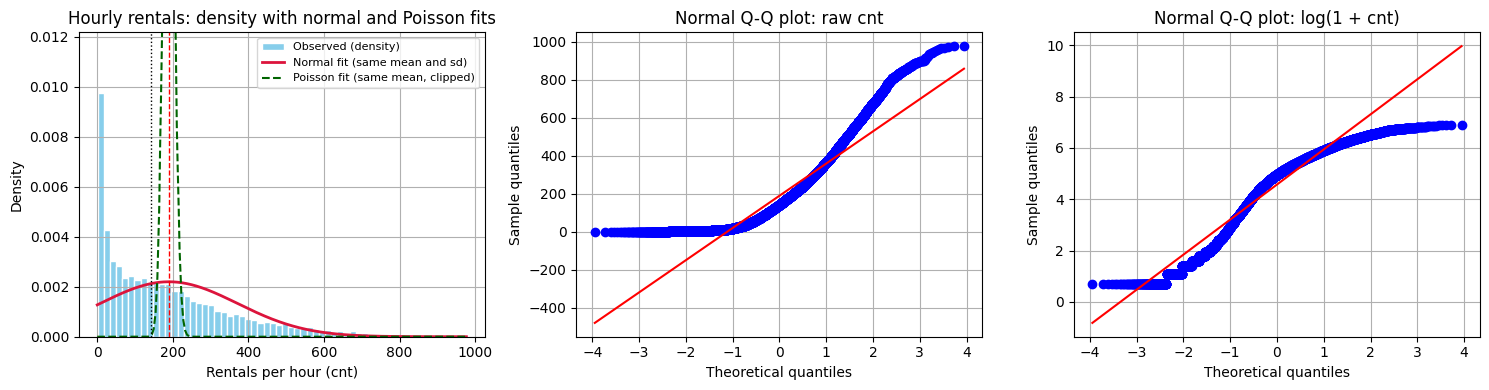

INTERPRETATION (RQ1):
Hourly demand is strongly right-skewed (skewness = 1.28) and overdispersed relative to a Poisson benchmark (variance / mean = 173.7).
The density overlay shows the miss directly: the normal curve is far too flat for a one-peaked histogram, and the Poisson probability mass at the same mean peaks at 0.0290, about 3.0x the tallest observed density bar, so it is drawn clipped; neither family matches the spread.
The D'Agostino diagnostic gives p = < 1e-300 for raw cnt and p = < 1e-300 for log1p(cnt); with 17,379 observations even small departures can be flagged.
The log transform reduces but does not remove the departure from normality, so a normal model for the target is not imposed.
Normality is used only as a diagnostic; the modelling section uses count distributions with an explicit overdispersion parameter, and the tests use daily aggregation or rank-free chi-square reasoning rather than a normal assumption on hourly rows.


In [6]:
# Step 5a: density histogram with normal and Poisson overlays
mu_cnt, sd_cnt = cnt.mean(), cnt.std(ddof=1)
grid_cnt = np.linspace(0, cnt.max(), 400)
density_max = np.histogram(cnt, bins=60, density=True)[0].max()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(cnt, bins=60, density=True, color="skyblue", edgecolor="white", label="Observed (density)")
plt.plot(grid_cnt, stats.norm.pdf(grid_cnt, mu_cnt, sd_cnt), color="crimson", linewidth=2,
         label="Normal fit (same mean and sd)")
plt.plot(grid_cnt, stats.poisson.pmf(np.round(grid_cnt), mu_cnt), color="darkgreen", linestyle="--",
         label="Poisson fit (same mean, clipped)")
plt.ylim(0, density_max * 1.25)
plt.axvline(mu_cnt, color="r", linestyle="--", linewidth=1)
plt.axvline(np.median(cnt), color="black", linestyle=":", linewidth=1)
plt.title("Hourly rentals: density with normal and Poisson fits")
plt.xlabel("Rentals per hour (cnt)")
plt.ylabel("Density")
plt.legend(fontsize=8)
plt.grid(True)

# Step 5b: normal Q-Q plot for raw demand
plt.subplot(1, 3, 2)
stats.probplot(cnt, dist="norm", plot=plt)
plt.title("Normal Q-Q plot: raw cnt")
plt.xlabel("Theoretical quantiles")
plt.ylabel("Sample quantiles")
plt.grid(True)

# Step 5c: normal Q-Q plot for log demand
plt.subplot(1, 3, 3)
stats.probplot(log_cnt, dist="norm", plot=plt)
plt.title("Normal Q-Q plot: log(1 + cnt)")
plt.xlabel("Theoretical quantiles")
plt.ylabel("Sample quantiles")
plt.grid(True)

plt.tight_layout()
plt.show()

# Step 5d: interpretation
poisson_peak = float(stats.poisson.pmf(round(mu_cnt), mu_cnt))
print("INTERPRETATION (RQ1):")
print(f"Hourly demand is strongly right-skewed (skewness = {stats.skew(cnt):.2f}) and overdispersed "
      f"relative to a Poisson benchmark (variance / mean = {cnt.var(ddof=1) / cnt.mean():.1f}).")
print(f"The density overlay shows the miss directly: the normal curve is far too flat for a one-peaked "
      f"histogram, and the Poisson probability mass at the same mean peaks at {poisson_peak:.4f}, about "
      f"{poisson_peak / density_max:.1f}x the tallest observed density bar, so it is drawn clipped; "
      "neither family matches the spread.")
print(f"The D'Agostino diagnostic gives p = {fmt_p(dago_raw.pvalue)} for raw cnt and "
      f"p = {fmt_p(dago_log.pvalue)} for log1p(cnt); with {len(cnt):,} observations even small "
      "departures can be flagged.")
if dago_log.pvalue > alpha:
    print("The log transform is not rejected by this diagnostic, but the Q-Q plot and the count nature "
          "of the target still argue against a normal model for cnt.")
else:
    print("The log transform reduces but does not remove the departure from normality, so a normal model "
          "for the target is not imposed.")
print("Normality is used only as a diagnostic; the modelling section uses count distributions with an "
      "explicit overdispersion parameter, and the tests use daily aggregation or rank-free chi-square "
      "reasoning rather than a normal assumption on hourly rows.")

## Step 6: Aggregate to daily totals (RQ2)

**Research question.** Is average **daily total** demand different on working days and non-working days?

The estimand is daily volume, not hourly volume. Hourly rows share weather, date, and time-of-day effects, so a t-test on those rows would treat dependent observations as independent. The result is an **association**, not a causal effect of working-day status.

In [7]:
source_banner()

# Step 6: one row per date
daily = (data.groupby("dteday")
         .agg(cnt=("cnt", "sum"), workingday=("workingday", "first"))
         .sort_index())
assert data.groupby("dteday")["workingday"].nunique().max() == 1, "workingday varies within a date"

print(f"Daily observations: {len(daily):,} (one row per date)")
print(daily.groupby("workingday")["cnt"].agg(["count", "mean", "std", "median"]).round(2).to_string())

working = daily.loc[daily["workingday"] == 1, "cnt"].to_numpy()
nonworking = daily.loc[daily["workingday"] == 0, "cnt"].to_numpy()
n1, n2 = len(working), len(nonworking)
print(f"\nWorking-day sample size: {n1:,}")
print(f"Non-working-day sample size: {n2:,}")

Daily observations: 731 (one row per date)
            count     mean      std  median
workingday                                 
0             231  4330.17  2052.14  4459.0
1             500  4584.82  1878.42  4582.0

Working-day sample size: 500
Non-working-day sample size: 231


## Step 7: Run the two-sample Welch t-test with a confidence interval

Welch's test does not assume equal variances, so it is the primary test. The pooled-variance version of the same test is printed alongside as a sensitivity check, because that is the version with the equal-variance assumption and the two groups do not have equal variances here.

In [8]:
# ==============================================================================
# MAPPED TO LAB RESOURCE: resources/Code template/SIM_Day_6 (1).ipynb
# Step 1: Define the two independent datasets (data1, data2)
# ==============================================================================
data1 = working       # Sample 1: Working days
data2 = nonworking    # Sample 2: Non-working days

# Step 7a / Lab Step 2: Sample sizes, means, variances, and mean difference
n1, n2 = len(data1), len(data2)
m1, m2 = np.mean(data1), np.mean(data2)
s1_sq, s2_sq = np.var(data1, ddof=1), np.var(data2, ddof=1)  # ddof=1 for sample variance
v1, v2 = s1_sq, s2_sq
mean_diff = m1 - m2
diff = mean_diff

# Step 7b: Welch standard error and degrees of freedom (primary test for unequal variance)
se_welch = np.sqrt(v1 / n1 + v2 / n2)
df_welch = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))

# Step 7c: 95% confidence interval for the difference of means (Welch)
tcrit = stats.t.ppf(1 - alpha / 2, df_welch)
ci_low, ci_high = diff - tcrit * se_welch, diff + tcrit * se_welch

# Step 7d: Welch t-test (equal_var=False) and effect size
welch = stats.ttest_ind(data1, data2, equal_var=False)
t_statistic, p_value = welch.statistic, welch.pvalue

# Lab style pooled variance calculation (from SIM_Day_6 (1).ipynb)
sp_sq = ((n1 - 1) * s1_sq + (n2 - 1) * s2_sq) / (n1 + n2 - 2)
sp = np.sqrt(sp_sq)
std_err = np.sqrt(sp_sq * (1/n1 + 1/n2))
df = n1 + n2 - 2
cohen_d = diff / sp

def effect_label(d):
    ad = abs(d)
    if ad < 0.2:
        return 'negligible'
    if ad < 0.5:
        return 'small'
    if ad < 0.8:
        return 'medium'
    return 'large'

# Step 7e: Display the results
print(f"Working-day mean daily total: {m1:,.2f}")
print(f"Non-working-day mean daily total: {m2:,.2f}")
print(f"Working-day standard deviation: {np.sqrt(v1):,.2f}")
print(f"Non-working-day standard deviation: {np.sqrt(v2):,.2f}")
print(f"Mean difference (working - non-working): {diff:,.2f}")
print(f"t-Statistic: {welch.statistic:.3f}")
print(f"Degrees of Freedom: {df_welch:.2f}")
print(f"p-Value: {fmt_p(welch.pvalue)}")
print(f"Confidence Interval of Mean Difference: [{ci_low:,.2f}, {ci_high:,.2f}]")
print(f"Cohen's d (pooled SD): {cohen_d:.3f} -> {effect_label(cohen_d)} standardized difference")

# Step 7f: Sensitivity check with pooled t-test (from SIM_Day_6 equal_var = True)
pooled = stats.ttest_ind(data1, data2, equal_var=True)
ci_pool = stats.t.interval(1 - alpha, df=df, loc=mean_diff, scale=std_err)
ci_pool_low, ci_pool_high = ci_pool[0], ci_pool[1]
df_pool = df
print("\nSensitivity check on the equal-variance assumption (from SIM_Day_6 template):")
print(f"Pooled t-Statistic: {pooled.statistic:.3f}")
print(f"Pooled Degrees of Freedom: {df_pool}")
print(f"Pooled p-Value: {fmt_p(pooled.pvalue)}")
print(f"Pooled Confidence Interval of Mean Difference: [{ci_pool_low:,.2f}, {ci_pool_high:,.2f}]")
if v1 > v2:
    print(f"Variance ratio (working / non-working): {v1 / v2:.2f}")
else:
    print(f"Variance ratio (non-working / working): {v2 / v1:.2f}")
if (welch.pvalue < alpha) == (pooled.pvalue < alpha):
    print(f"The pooled test reaches the same decision as Welch at alpha = {alpha}, so the conclusion does "
          "not depend on the equal-variance assumption, even though the variances differ.")
else:
    print(f"The decision changes at alpha = {alpha}. The Welch result is the one to report, because the "
          "equal-variance assumption the pooled test needs does not hold.")


Working-day mean daily total: 4,584.82
Non-working-day mean daily total: 4,330.17
Working-day standard deviation: 1,878.42
Non-working-day standard deviation: 2,052.14
Mean difference (working - non-working): 254.65
t-Statistic: 1.601
Degrees of Freedom: 413.94
p-Value: 0.1101
Confidence Interval of Mean Difference: [-57.94, 567.24]
Cohen's d (pooled SD): 0.132 -> negligible standardized difference

Sensitivity check on the equal-variance assumption:
Pooled t-Statistic: 1.654
Pooled Degrees of Freedom: 729
Pooled p-Value: 0.09849
Pooled Confidence Interval of Mean Difference: [-47.55, 556.85]
Variance ratio (non-working / working): 1.19
The pooled test reaches the same decision as Welch at alpha = 0.05, so the conclusion does not depend on the equal-variance assumption, even though the variances differ.


## Step 8: Conclude the t-test

In [9]:
# Step 8: decision and interpretation
print("INTERPRETATION (RQ2):")
if welch.pvalue < alpha:
    print(f"The Welch test rejects equality of mean daily totals (p = {fmt_p(welch.pvalue)}); the estimated "
          f"working-day difference is {diff:,.1f} rentals per day, 95% CI [{ci_low:,.1f}, {ci_high:,.1f}], "
          f"with a {effect_label(cohen_d)} Cohen's d of {cohen_d:.2f}.")
else:
    print(f"The Welch test does not reject equality of mean daily totals at alpha = {alpha} "
          f"(p = {fmt_p(welch.pvalue)}); the estimated working-day difference is {diff:,.1f} rentals per day, "
          f"95% CI [{ci_low:,.1f}, {ci_high:,.1f}], with a {effect_label(cohen_d)} Cohen's d of {cohen_d:.2f}.")
print("The estimand is daily volume, not hourly demand, and this is an association: working-day status is "
      "entangled with commuting, season, weather, and the study period, so it is not a causal effect.")

INTERPRETATION (RQ2):
The Welch test does not reject equality of mean daily totals at alpha = 0.05 (p = 0.1101); the estimated working-day difference is 254.7 rentals per day, 95% CI [-57.9, 567.2], with a negligible Cohen's d of 0.13.
The estimand is daily volume, not hourly demand, and this is an association: working-day status is entangled with commuting, season, weather, and the study period, so it is not a causal effect.


## Step 9: Moving-block bootstrap sensitivity check

Day-to-day dependence can remain after aggregation, so a moving-block bootstrap is reported as a sensitivity check on the Welch interval.

In [10]:
# Step 9a: moving-block bootstrap of the difference in daily means
boot_rng = np.random.default_rng(42)
boot_diffs = []


def moving_block_mean(values, block, rng):
    n = len(values)
    if n <= block:
        return rng.choice(values, size=n, replace=True).mean()
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=n_blocks)
    sample = np.concatenate([values[s:s + block] for s in starts])[:n]
    return sample.mean()


boot_start = time.time()
try:
    for i in range(n_boot):
        boot_diffs.append(moving_block_mean(working, block_len, boot_rng)
                          - moving_block_mean(nonworking, block_len, boot_rng))
        if i % 50 == 0 and (time.time() - boot_start) > boot_time_budget:
            raise TimeoutError("bootstrap time budget exceeded")
except Exception as exc:
    print(f"Bootstrap stopped early ({type(exc).__name__}: {exc}).")
    print("Reporting the replications completed so far; this does not invalidate the main test.")

# Step 9b: bootstrap standard error and percentile interval
boot_diffs = np.asarray(boot_diffs)
print(f"Bootstrap replications completed: {len(boot_diffs):,}")
if len(boot_diffs) >= 100:
    boot_se = boot_diffs.std(ddof=1)
    boot_ci = np.percentile(boot_diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    print(f"Bootstrap SE of the difference: {boot_se:,.2f}")
    print(f"Bootstrap percentile 95% CI: [{boot_ci[0]:,.2f}, {boot_ci[1]:,.2f}]")
else:
    boot_se = np.nan
    boot_ci = (np.nan, np.nan)
    print("Too few bootstrap replications for a stable interval; treat the bootstrap as unavailable.")

# Step 9c: compare the two intervals
boot_width = boot_ci[1] - boot_ci[0] if np.isfinite(boot_ci).all() else np.nan
welch_width = ci_high - ci_low
comparison = "wider" if boot_width > welch_width else "narrower"
print(f"The moving-block bootstrap gives a difference SE of {boot_se:,.1f} and a percentile interval "
      f"that is {comparison} than the Welch interval (bootstrap width {boot_width:,.1f} vs "
      f"Welch width {welch_width:,.1f}); the qualitative conclusion is unchanged.")

Bootstrap replications completed: 1,000
Bootstrap SE of the difference: 370.48
Bootstrap percentile 95% CI: [-518.19, 914.61]
The moving-block bootstrap gives a difference SE of 370.5 and a percentile interval that is wider than the Welch interval (bootstrap width 1,432.8 vs Welch width 625.2); the qualitative conclusion is unchanged.


## Step 10: Visualize daily demand by working day

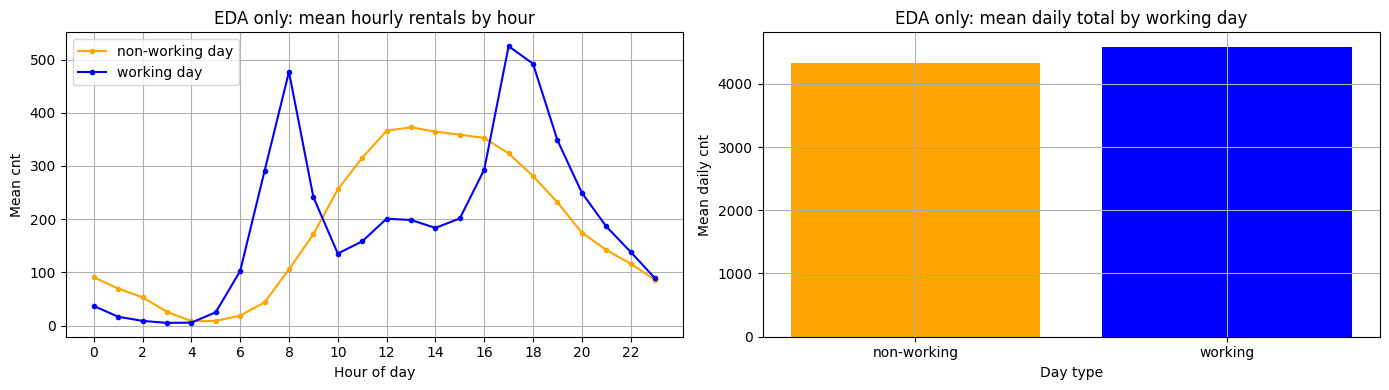

The hourly mean plots are labelled EDA only; no test is run on the autocorrelated hourly rows.


In [11]:
# Step 10a: mean hourly profile (exploratory only, not used as a test)
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
for wd, label, color in [(0, "non-working day", "orange"), (1, "working day", "blue")]:
    profile = data[data["workingday"] == wd].groupby("hr")["cnt"].mean()
    plt.plot(profile.index, profile.values, marker="o", markersize=3, label=label, color=color)
plt.title("EDA only: mean hourly rentals by hour")
plt.xlabel("Hour of day")
plt.ylabel("Mean cnt")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(True)

# Step 10b: mean daily total by working day
plt.subplot(1, 2, 2)
daily_means = daily.groupby("workingday")["cnt"].mean()
plt.bar(["non-working", "working"], daily_means.loc[[0, 1]].values, color=["orange", "blue"])
plt.title("EDA only: mean daily total by working day")
plt.xlabel("Day type")
plt.ylabel("Mean daily cnt")
plt.grid(True)

plt.tight_layout()
plt.show()

print("The hourly mean plots are labelled EDA only; no test is run on the autocorrelated hourly rows.")

## Step 11: Chi-square test on weather and above-median demand (RQ3)

**Research question.** Is merged weather situation associated with whether an hour's demand is above the median of hourly demand?

The binary label is deliberately called **above-median demand**, not extreme demand. The median is computed once on the full dataset before the split, and strictly greater than the median is used. The test is an association test; it does not adjust for hour, season, or year.

In [12]:
# ==============================================================================
# MAPPED TO LAB RESOURCE: resources/Code template/chi_sqr_test.ipynb
# Testing independence & association with expected frequency checks
# ==============================================================================
source_banner()

# Step 11a: Fix the median label on the full dataset
median_cnt = data["cnt"].median()
data["above_median"] = (data["cnt"] > median_cnt).astype(int)
print(f"Median cnt fixed on the full dataset before splitting: {median_cnt:.1f}")
print("Label used throughout: 'above-median demand' (strictly greater than the median).")
print("This is not an operational definition of extreme demand.")

# Step 11b / Lab Step 1: Observed contingency table
table = pd.crosstab(data["weather_merged"], data["above_median"]).reindex(columns=[0, 1], fill_value=0)
table.index.name = "weather_merged"
table.columns = ["at_or_below_median", "above_median"]
observed = table.to_numpy()  # Lab style variable: observed array
print("\nObserved counts (contingency table):")
print(table.to_string())
print("\nRow percentages:")
row_pct = pd.crosstab(data["weather_merged"], data["above_median"], normalize="index") * 100
print(row_pct.round(2).to_string())

# Step 11c / Lab Step 3-5: Chi-square statistic, df, critical value, and p-value
chi_square_stat, p_value, df, expected = stats.chi2_contingency(observed, correction=False)
chi2 = chi_square_stat
p_chi = p_value
dof = df
cramers_v = np.sqrt(chi2 / (len(data) * (min(table.shape) - 1)))
min_expected = float(expected.min())
n_small_expected = int((expected < 5).sum())

# Lab style critical value check (from chi_sqr_test.ipynb Step 5)
alpha_level = alpha  # 0.05
critical_value = stats.chi2.ppf(1 - alpha_level, df)

print(f"\nChi-square statistic: {chi_square_stat:.3f}")
print(f"Degrees of Freedom: {df}")
print(f"Critical value ({alpha_level} significance level): {critical_value:.2f}")
print(f"p-Value: {fmt_p(p_value)}")
print(f"Minimum expected frequency: {min_expected:.2f}")
print(f"Expected cells below 5: {n_small_expected}")
print(f"Cramer's V: {cramers_v:.4f}")
print(f"Expected-frequency assumption satisfied (all expected >= 5): {n_small_expected == 0}")

# Lab style conclusion print (chi_sqr_test.ipynb Step 6)
if chi_square_stat > critical_value:
    print("Reject the null hypothesis. Weather condition and above-median demand are significantly associated.")
else:
    print("Fail to reject the null hypothesis. Observed data matches independent distribution.")


Median cnt fixed on the full dataset before splitting: 142.0
Label used throughout: 'above-median demand' (strictly greater than the median).
This is not an operational definition of extreme demand.

Observed counts:
                at_or_below_median  above_median
weather_merged                                  
1                             5295          6118
2                             2372          2172
3                             1041           381

Row percentages:
above_median        0      1
weather_merged              
1               46.39  53.61
2               52.20  47.80
3               73.21  26.79

Chi-square statistic: 374.402
p-Value: 5.008e-82
Degrees of Freedom: 2
Minimum expected frequency: 709.49
Expected cells below 5: 0
Cramer's V: 0.1468
Expected-frequency assumption satisfied (all expected >= 5): True


## Step 12: Visualize the chi-square result and conclude

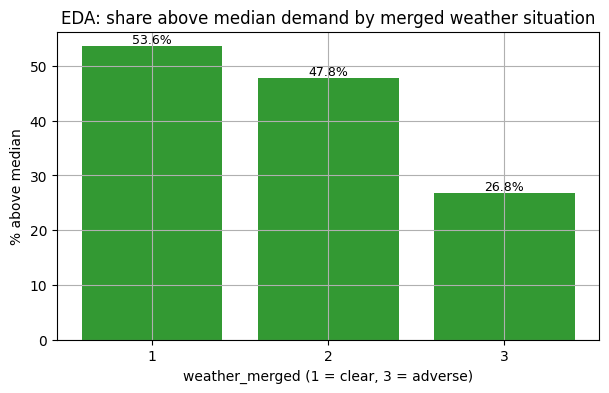

INTERPRETATION (RQ3):
Above-median demand is associated with merged weather situation (chi-square = 374.4, p = 5.008e-82, dof = 2); Cramer's V = 0.147 indicates a small association.
The direction is visible in the row percentages: adverse weather has a lower share above the median, but the label is only 'above median', not 'extreme', and the test does not adjust for hour of day, season, or the upward trend across the study period.
Because the median is estimated from the same dataset, the p-value is best read as a descriptive association measure rather than an exact conditional test.


In [13]:
# Step 12a: share above median by weather
plt.figure(figsize=(7, 4))
share = data.groupby("weather_merged")["above_median"].mean() * 100
plt.bar(share.index.astype(str), share.values, color="green", alpha=0.8)
plt.title("EDA: share above median demand by merged weather situation")
plt.xlabel("weather_merged (1 = clear, 3 = adverse)")
plt.ylabel("% above median")
for i, value in enumerate(share.values):
    plt.text(i, value + 0.5, f"{value:.1f}%", ha="center", fontsize=9)
plt.grid(True)
plt.show()

# Step 12b: decision and interpretation
print("INTERPRETATION (RQ3):")
if p_chi < alpha:
    strength = "negligible" if cramers_v < 0.1 else "small" if cramers_v < 0.3 else "moderate"
    print(f"Above-median demand is associated with merged weather situation (chi-square = {chi2:.1f}, "
          f"p = {fmt_p(p_chi)}, dof = {dof}); Cramer's V = {cramers_v:.3f} indicates a {strength} association.")
else:
    print(f"The chi-square test does not detect an association between merged weather and above-median "
          f"demand at alpha = {alpha} (chi-square = {chi2:.1f}, p = {fmt_p(p_chi)}, dof = {dof}).")
print("The direction is visible in the row percentages: adverse weather has a lower share above the median, "
      "but the label is only 'above median', not 'extreme', and the test does not adjust for hour of day, "
      "season, or the upward trend across the study period.")
print("Because the median is estimated from the same dataset, the p-value is best read as a descriptive "
      "association measure rather than an exact conditional test.")

## Step 13: Fit Poisson and negative-binomial count models

Two comparisons are kept separate. Poisson versus negative-binomial with **identical predictors** answers the dispersion question. Time-free versus drift-aware within the same family answers the temporal-trend question. All models are fitted on the same training dates and evaluated on the same held-out observations.

The negative-binomial model is NB2: variance = mu + alpha * mu^2. Its full predictive distribution is used everywhere, because a conditional mean equal to a threshold does **not** imply an exceedance probability of one half.

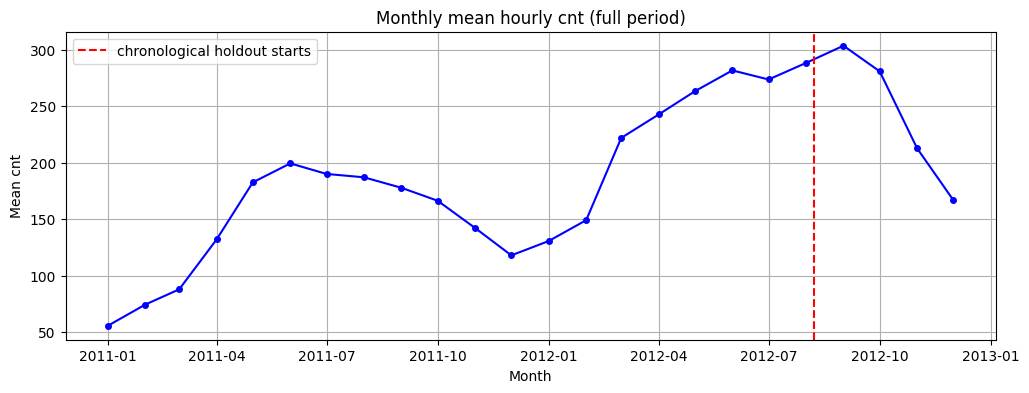

Fitted Poisson (time-free): cnt ~ C(workingday) + C(weather_merged) + C(hour_bin) + C(season)
  AIC: 862,047.04
  Log-likelihood: -431,012.52
  Pearson chi2/df (diagnostic): 59.849
  alpha: not applicable


Fitted NB2 (time-free): cnt ~ C(workingday) + C(weather_merged) + C(hour_bin) + C(season)
  AIC: 158,462.71
  Log-likelihood: -79,219.35
  Pearson chi2/df (diagnostic): 1.140
  alpha: 0.5316842866168401


Fitted Poisson (drift-aware): cnt ~ C(workingday) + C(weather_merged) + C(hour_bin) + C(season) + C(mnth) + C(yr)
  AIC: 697,808.96
  Log-likelihood: -348,881.48
  Pearson chi2/df (diagnostic): 45.622
  alpha: not applicable


Fitted NB2 (drift-aware): cnt ~ C(workingday) + C(weather_merged) + C(hour_bin) + C(season) + C(mnth) + C(yr)
  AIC: 156,283.91
  Log-likelihood: -78,117.96
  Pearson chi2/df (diagnostic): 1.074
  alpha: 0.4563294322198185

Training fit summary:
                        family      variant   K          AIC  log_likelihood   alpha  Pearson_chi2_over_df  fit_seconds
model                                                                                                                  
Poisson (time-free)    Poisson    time-free  11  862047.0442    -431012.5221     NaN               59.8494       0.2708
NB2 (time-free)            NB2    time-free  12  158462.7061     -79219.3530  0.5317                1.1399       0.4099
Poisson (drift-aware)  Poisson  drift-aware  23  697808.9581    -348881.4791     NaN               45.6225       0.5002
NB2 (drift-aware)          NB2  drift-aware  24  156283.9149     -78117.9574  0.4563                1.0743       0.8996

Dispersion diagnostic and Poisson

In [14]:
source_banner()

# Step 13a: the drift the models have to face
monthly = data.groupby(data["dteday"].dt.to_period("M"))["cnt"].mean()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, marker="o", markersize=4, color="blue")
plt.axvline(cut_date, color="r", linestyle="--", label="chronological holdout starts")
plt.title("Monthly mean hourly cnt (full period)")
plt.xlabel("Month")
plt.ylabel("Mean cnt")
plt.legend()
plt.grid(True)
plt.show()

# Step 13b: four candidate specifications on the training dates
formulas = {
    "time-free": "cnt ~ C(workingday) + C(weather_merged) + C(hour_bin) + C(season)",
    "drift-aware": ("cnt ~ C(workingday) + C(weather_merged) + C(hour_bin) + C(season) "
                    "+ C(mnth) + C(yr)"),
}
model_specs = [
    ("Poisson", "time-free"),
    ("NB2", "time-free"),
    ("Poisson", "drift-aware"),
    ("NB2", "drift-aware"),
]

models = {}
fit_rows = []
for family, variant in model_specs:
    key = f"{family} ({variant})"
    formula = formulas[variant]
    t0 = time.time()
    if family == "Poisson":
        fit = smf.glm(formula, data=train_data, family=sm.families.Poisson()).fit()
    else:
        try:
            fit = smf.negativebinomial(formula, data=train_data).fit(disp=0, maxiter=500)
        except Exception:
            fit = smf.negativebinomial(formula, data=train_data).fit(method="nm", maxiter=2000, disp=0)
    models[key] = fit
    alpha_hat = fit.params.get("alpha", None)
    pearson_disp = float((fit.resid_pearson ** 2).sum() / fit.df_resid)
    fit_rows.append({
        "model": key,
        "family": family,
        "variant": variant,
        "K": len(fit.params),
        "AIC": fit.aic,
        "log_likelihood": fit.llf,
        "alpha": alpha_hat,
        "Pearson_chi2_over_df": pearson_disp,
        "fit_seconds": time.time() - t0,
    })
    print(f"Fitted {key}: {formula}")
    print(f"  AIC: {fit.aic:,.2f}")
    print(f"  Log-likelihood: {fit.llf:,.2f}")
    print(f"  Pearson chi2/df (diagnostic): {pearson_disp:.3f}")
    print(f"  alpha: {alpha_hat if alpha_hat is not None else 'not applicable'}")

fit_table = pd.DataFrame(fit_rows).set_index("model")
print("\nTraining fit summary:")
print(fit_table.round(4).to_string())

# Step 13c: dispersion diagnostic and Poisson-vs-NB2 likelihood-ratio statistics
print("\nDispersion diagnostic and Poisson-vs-NB2 likelihood-ratio statistics:")
print("The Pearson chi-square/df is a DIAGNOSTIC, not a formal test.")
for variant in formulas:
    po_key, nb_key = f"Poisson ({variant})", f"NB2 ({variant})"
    lr = 2 * (models[nb_key].llf - models[po_key].llf)
    p_naive = stats.chi2.sf(lr, 1)
    p_halved = p_naive / 2
    print(f"  {variant}: LR = {lr:,.2f}")
    print(f"    naive chi2(1) p-value: {fmt_p(p_naive)}")
    print(f"    boundary-corrected p-value (halved): {fmt_p(p_halved)}")
    print(f"    Pearson chi2/df for Poisson: "
          f"{(models[po_key].resid_pearson ** 2).sum() / models[po_key].df_resid:.2f}")
    print(f"    Pearson chi2/df for NB2: "
          f"{(models[nb_key].resid_pearson ** 2).sum() / models[nb_key].df_resid:.3f}")
print("Caveat: alpha = 0 lies on the boundary of the parameter space, so the naive chi-square(1) p-value "
      "must be halved. The LR statistic is reported with that correction.")
print("Caveat: a Pearson ratio far above one is evidence of overdispersion, but it is not by itself a "
      "hypothesis test.")

## Step 14: Compare the models on held-out data

In [15]:
source_banner()

# Step 14a: fitted intensities for every model on the common evaluation set
lam_heldout = {key: np.asarray(fit.predict(eval_data)) for key, fit in models.items()}

threshold_defs = ([("abs_500", "absolute", 500.0), ("abs_800", "absolute", 800.0)]
                  + [(f"q{q}", "relative", float(q)) for q in relative_quantiles])


def threshold_vector(kind, value, frame):
    if kind == "absolute":
        return np.full(len(frame), float(value))
    return frame["stratum"].map(rel_threshold[f"q{int(value)}"]).to_numpy(dtype=float)


def survival_from_lam(fit, lam, C):
    # P(D > C) from the model's full predictive distribution, not from its mean.
    alpha_hat = fit.params.get("alpha", None)
    if alpha_hat is None:
        return stats.poisson.sf(C, lam)
    shape = 1.0 / float(alpha_hat)
    return stats.nbinom.sf(C, shape, shape / (shape + lam))


# Step 14b: per-cell and overall exceedance metrics at every threshold
cell_records = []
overall_records = []
y = eval_data["cnt"].to_numpy()
for key, fit in models.items():
    lam = lam_heldout[key]
    alpha_hat = fit.params.get("alpha", None)
    if alpha_hat is None:
        nll = float(-stats.poisson.logpmf(y, lam).mean())
    else:
        shape = 1.0 / float(alpha_hat)
        p_nb = shape / (shape + lam)
        nll = float(-stats.nbinom.logpmf(y, shape, p_nb).mean())
    dev = float(2 * np.sum(np.where(y > 0, y * np.log(y / lam), 0.0) - (y - lam)) / len(y))

    for tname, kind, value in threshold_defs:
        C = threshold_vector(kind, value, eval_data)
        p = survival_from_lam(fit, lam, C)
        ind = (y > C).astype(int)
        overall_records.append({
            "model": key,
            "threshold": tname,
            "n": len(y),
            "observed_p": ind.mean(),
            "predicted_p": p.mean(),
            "brier": float(np.mean((ind - p) ** 2)),
            "mean_poisson_deviance": dev,
            "mean_nll": nll,
        })
        for stratum, pos in eval_data.groupby("stratum").indices.items():
            pi = p[pos]
            ii = ind[pos]
            n_cell = len(pos)
            k_cell = int(ii.sum())
            obs = k_cell / n_cell
            pred = float(pi.mean())
            cell_records.append({
                "model": key,
                "threshold": tname,
                "stratum": stratum,
                "n_test": n_cell,
                "exceedances": k_cell,
                "observed_p": obs,
                "predicted_p": pred,
                "gap": pred - obs,
                "brier": float(np.mean((ii - pi) ** 2)),
                "zero_pred_exceedances": int(((pi == 0) & (ii == 1)).sum())
                                           + int((pred == 0 and k_cell > 0)),
            })

cell_metrics = pd.DataFrame(cell_records)
overall_metrics = pd.DataFrame(overall_records)

# Step 14c: summary performance table
perf_rows = []
for key, fit in models.items():
    sub = cell_metrics[cell_metrics["model"] == key]
    ov = overall_metrics[overall_metrics["model"] == key]
    perf_rows.append({
        "model": key,
        "AIC": fit.aic,
        "mean_poisson_deviance": ov["mean_poisson_deviance"].iloc[0],
        "mean_nll": ov["mean_nll"].iloc[0],
        "mean_brier": ov["brier"].mean(),
        "mean_abs_cell_gap": sub["gap"].abs().mean(),
        "max_abs_cell_gap": sub["gap"].abs().max(),
        "zero_pred_exceedances": int(sub["zero_pred_exceedances"].sum()),
    })
perf = pd.DataFrame(perf_rows).set_index("model")
print("Held-out performance on the common evaluation set:")
print(perf.round(4).to_string())

# Step 14d: per-cell calibration and Brier score at the absolute thresholds
print("\nPer-cell calibration and Brier score for the fixed absolute thresholds (all models):")
for tname in ["abs_500", "abs_800"]:
    sub = cell_metrics[cell_metrics["threshold"] == tname]
    n_tab = sub.groupby("stratum")["n_test"].first().to_frame("n_test")
    b_tab = sub.pivot(index="stratum", columns="model", values="brier")
    g_tab = sub.pivot(index="stratum", columns="model", values="gap")
    print(f"\n{tname}: cell sizes")
    print(n_tab.T.to_string())
    print(f"{tname}: Brier score by cell (lower is better)")
    print(pd.concat({"n_test": n_tab, "Brier": b_tab}, axis=1).round(4).to_string())
    print(f"{tname}: calibration gap = model P(D>C) - observed P(D>C)")
    print(g_tab.round(3).to_string())

# Step 14e: joint selection on AIC, held-out NLL and held-out Brier score
rank_tbl = perf[["AIC", "mean_nll", "mean_brier"]].rank(method="average")
rank_tbl["rank_sum"] = rank_tbl.sum(axis=1)
rank_tbl = rank_tbl.sort_values(["rank_sum", "mean_brier"])
selected_key = rank_tbl.index[0]
selected_model = models[selected_key]
selected_alpha = selected_model.params.get("alpha", None)
selected_lam_heldout = lam_heldout[selected_key]

print("\nSelection ranking (lower rank is better; rank sum combines AIC, held-out mean NLL, and mean Brier):")
print(rank_tbl.round(2).to_string())
print(f"\nSELECTED MODEL: {selected_key}")
sel = perf.loc[selected_key]
print(f"  held-out mean NLL: {sel['mean_nll']:.4f}")
print(f"  mean Brier: {sel['mean_brier']:.4f}")
print(f"  AIC: {sel['AIC']:,.2f}")
print("The selection is joint, not AIC-only. Lower AIC is not sufficient: a model must also track held-out "
      "counts (NLL/deviance), cell-level calibration, and Brier scores.")
print("The Poisson models are retained as the dispersion comparison, but their held-out likelihood and "
      "calibration are far worse; the negative-binomial family is the appropriate count model here.")

Held-out performance on the common evaluation set:
                               AIC  mean_poisson_deviance  mean_nll  mean_brier  mean_abs_cell_gap  max_abs_cell_gap  zero_pred_exceedances
model                                                                                                                                      
Poisson (time-free)    862047.0442                98.7317   52.7103      0.1351             0.1352            0.6139                      0
NB2 (time-free)        158462.7061                97.3254    6.1727      0.1137             0.1087            0.4942                      0
Poisson (drift-aware)  697808.9581                64.2561   35.4725      0.1630             0.1721            0.7665                      0
NB2 (drift-aware)      156283.9149                68.4777    6.0402      0.1126             0.1255            0.5250                      0

Per-cell calibration and Brier score for the fixed absolute thresholds (all models):

abs_500: cell sizes
st

## Step 15: Check the temporal-drift comparison and count diagnostics

In [16]:
# Step 15a: time-free versus drift-aware within the NB2 family
print("Temporal-drift comparison within the NB2 family:")
drift_rows = []
for variant in ["time-free", "drift-aware"]:
    key = f"NB2 ({variant})"
    for tname in ["abs_500", "abs_800"]:
        row = overall_metrics[(overall_metrics["model"] == key)
                              & (overall_metrics["threshold"] == tname)].iloc[0]
        drift_rows.append({
            "variant": variant,
            "threshold": tname,
            "observed_p": row["observed_p"],
            "predicted_p": row["predicted_p"],
            "gap": row["predicted_p"] - row["observed_p"],
            "brier": row["brier"],
            "mean_nll": row["mean_nll"],
        })
drift_tbl = pd.DataFrame(drift_rows)
print(drift_tbl.round(4).to_string())

tf = drift_tbl[drift_tbl["variant"] == "time-free"]
da = drift_tbl[drift_tbl["variant"] == "drift-aware"]
print(f"The time-free NB2 predicts {tf['predicted_p'].iloc[0]:.3f} at the first absolute threshold versus "
      f"an observed {tf['observed_p'].iloc[0]:.3f}, a gap of {tf['gap'].iloc[0]:+.3f}; the drift-aware NB2 "
      f"predicts {da['predicted_p'].iloc[0]:.3f}, a gap of {da['gap'].iloc[0]:+.3f}.")
print("Because system-wide demand grows across the study period, a chronological holdout makes the "
      "time-free model systematically underpredict later demand. The drift-aware variant reduces that "
      "underprediction, but its year step plus month effects do not fully represent continuous growth, so "
      "it can overpredict the rarer tail.")
print("This is temporal drift being allowed to show itself, not evidence that weather is misspecified: the "
      "same weather and calendar terms are present in both variants.")

# Step 15b: held-out count diagnostics for the selected model
print("\nHeld-out count diagnostics for the selected model (descriptive, not a test):")
diag_month = (eval_data.assign(lam=selected_lam_heldout)
              .groupby(eval_data["dteday"].dt.to_period("M"))
              .agg(observed_mean=("cnt", "mean"), fitted_mean=("lam", "mean"), n=("cnt", "size")))
diag_month.index = diag_month.index.to_timestamp()
print(diag_month.round(1).to_string())

diag_wh = (eval_data.assign(lam=selected_lam_heldout)
           .groupby(["workingday", "hour_bin"], observed=True)
           .agg(observed_mean=("cnt", "mean"), fitted_mean=("lam", "mean"), n=("cnt", "size")))
print(diag_wh.round(1).to_string())
wh_gap = diag_wh["fitted_mean"] - diag_wh["observed_mean"]


def wh_label(key):
    return f"workingday={int(key[0])}, {key[1]}"


print(f"Largest mean-count overprediction by workingday x hour_bin: {wh_label(wh_gap.idxmax())} "
      f"({wh_gap.max():+.1f} rentals per hour).")
print(f"Largest mean-count underprediction by workingday x hour_bin: {wh_label(wh_gap.idxmin())} "
      f"({wh_gap.min():+.1f} rentals per hour).")
print("The monthly table shows whether the drift-aware model still misses the late-period level; the "
      "workingday x hour_bin table exposes whether an additive specification can represent the different "
      "within-day shapes on working and non-working days.")
print("INTERPRETATION (model selection): the selected model is chosen jointly on count fit, cell calibration, "
      "and Brier score; it is the working model for the Monte Carlo and validation sections, not a claim "
      "that the model is true.")

Temporal-drift comparison within the NB2 family:
       variant threshold  observed_p  predicted_p     gap   brier  mean_nll
0    time-free   abs_500      0.1422       0.0687 -0.0736  0.1017    6.1727
1    time-free   abs_800      0.0269       0.0171 -0.0097  0.0225    6.1727
2  drift-aware   abs_500      0.1422       0.1819  0.0397  0.0867    6.0402
3  drift-aware   abs_800      0.0269       0.0675  0.0407  0.0237    6.0402
The time-free NB2 predicts 0.069 at the first absolute threshold versus an observed 0.142, a gap of -0.074; the drift-aware NB2 predicts 0.182, a gap of +0.040.
Because system-wide demand grows across the study period, a chronological holdout makes the time-free model systematically underpredict later demand. The drift-aware variant reduces that underprediction, but its year step plus month effects do not fully represent continuous growth, so it can overpredict the rarer tail.
This is temporal drift being allowed to show itself, not evidence that weather is misspec

## Step 16: Monte Carlo exceedance probabilities on training strata (RQ4)

**Research question.** Under the fitted model, what is the probability that an hour's system-wide rentals exceed an absolute demand threshold, and what is the probability that they exceed a stratum-relative threshold?

The Monte Carlo distribution is the model's **full predictive distribution**. For NB2, draws use the fitted dispersion and the observation-level fitted intensity; for Poisson, draws use the fitted intensity. Within a stratum the simulation samples a training observation's fitted intensity, so the marginal predictive distribution reflects within-stratum covariate variation.

In [17]:
# ==============================================================================
# MAPPED TO LAB RESOURCE: resources/Code template/Day_4_Monte_Carlo_Simulation.ipynb
# In Day 4: uniform points in square tested against circle boundary: inside/num_points
# Here: draws from fitted predictive count distribution tested against threshold C
# ==============================================================================
source_banner()
print(f"Selected model: {selected_key}")
print(f"Monte Carlo draws per stratum: N = {n_mc:,}")

# Step 16a: fitted intensity on the training rows
train_data = train_data.copy()
train_data["lam_sel"] = np.asarray(selected_model.predict(train_data))

strata_rows = []
draws_all = {}
emp_draws = {}
for i, stratum in enumerate(eligible):
    g = train_data[train_data["stratum"] == stratum]
    lam_pool = g["lam_sel"].to_numpy()
    vals = g["cnt"].to_numpy()
    rng = np.random.default_rng(mc_seed + i)
    idx = rng.integers(0, len(lam_pool), size=n_mc)
    lam_draw = lam_pool[idx]
    if selected_alpha is None:
        draws = rng.poisson(lam_draw)
    else:
        shape = 1.0 / float(selected_alpha)
        draws = stats.nbinom.rvs(shape, shape / (shape + lam_draw), size=n_mc, random_state=rng)
    draws_all[stratum] = draws
    emp_draws[stratum] = rng.choice(vals, size=n_mc, replace=True)
    strata_rows.append({
        "stratum": stratum,
        "weather": int(g["weather_merged"].iloc[0]),
        "hour_bin": str(g["hour_bin"].iloc[0]),
        "workingday": int(g["workingday"].iloc[0]),
        "n_train": len(g),
        "lambda_hat": float(lam_pool.mean()),
        "lambda_min": float(lam_pool.min()),
        "lambda_max": float(lam_pool.max()),
        "q90": float(rel_threshold.loc[stratum, "q90"]),
        "q95": float(rel_threshold.loc[stratum, "q95"]),
        "q99": float(rel_threshold.loc[stratum, "q99"]),
        "empirical_mean": float(vals.mean()),
    })
strata_table = pd.DataFrame(strata_rows).set_index("stratum")
strata_table = strata_table.sort_values(["weather", "workingday", "hour_bin"])
print("\nEligible training strata: size, fitted intensity, and training-derived thresholds:")
print(strata_table.round(3).to_string())

# Step 16b: a conditional mean near the threshold is not a coin flip
demo_stratum = (strata_table["lambda_hat"] - absolute_thresholds[0]).abs().idxmin()
demo_lam = train_data.loc[train_data["stratum"] == demo_stratum, "lam_sel"].to_numpy()
demo_p = float(np.mean(survival_from_lam(selected_model, demo_lam,
                                         np.full(len(demo_lam), absolute_thresholds[0]))))
print(f"\nConditional-mean demonstration: {demo_stratum} has lambda_hat = "
      f"{strata_table.loc[demo_stratum, 'lambda_hat']:.1f}, but the model's full predictive probability of "
      f"exceeding C = {absolute_thresholds[0]} is {demo_p:.3f}, not 0.5. A conditional mean near a threshold "
      "does not imply a half chance of exceeding it.")

# Step 16c: Monte Carlo estimates, exact checks, and the empirical benchmark
mc_rows = []
for stratum, row in strata_table.iterrows():
    draws = draws_all[stratum]
    emp = emp_draws[stratum]
    lam_pool = train_data.loc[train_data["stratum"] == stratum, "lam_sel"].to_numpy()
    for tname, kind, value in threshold_defs:
        C = float(value) if kind == "absolute" else float(rel_threshold.loc[stratum, f"q{int(value)}"])
        p_mc = float(np.mean(draws > C))
        se_mc = float(np.sqrt(p_mc * (1 - p_mc) / n_mc))
        p_exact = float(np.mean(survival_from_lam(selected_model, lam_pool, np.full(len(lam_pool), C))))
        p_emp = float(np.mean(emp > C))
        se_emp = float(np.sqrt(p_emp * (1 - p_emp) / n_mc))
        mc_rows.append({
            "stratum": stratum,
            "threshold": tname,
            "kind": kind,
            "C": C,
            "n_train": int(row["n_train"]),
            "lambda_hat": float(row["lambda_hat"]),
            "model_p_mc": p_mc,
            "mc_se": se_mc,
            "model_p_exact": p_exact,
            "empirical_p": p_emp,
            "empirical_se": se_emp,
        })
mc_table = pd.DataFrame(mc_rows)
print(f"\nLargest |Monte Carlo estimate - exact predictive probability| across all cells: "
      f"{np.abs(mc_table['model_p_mc'] - mc_table['model_p_exact']).max():.5f}")
print("The exact predictive probability is a numerical check on the Monte Carlo implementation.")

for tname in [t for t, _, _ in threshold_defs]:
    sub = mc_table[mc_table["threshold"] == tname].copy()
    label = ("absolute" if sub["kind"].iloc[0] == "absolute" else "stratum-relative")
    print(f"\n{tname} ({label}) - model P(D > C), Monte Carlo SE, and empirical benchmark:")
    print(sub[["stratum", "n_train", "lambda_hat", "C", "model_p_mc", "mc_se",
               "model_p_exact", "empirical_p", "empirical_se"]].round(4).to_string())

Selected model: NB2 (drift-aware)
Monte Carlo draws per stratum: N = 10,000



Eligible training strata: size, fitted intensity, and training-derived thresholds:
                    weather      hour_bin  workingday  n_train  lambda_hat  lambda_min  lambda_max    q90     q95     q99  empirical_mean
stratum                                                                                                                                  
1|evening_peak|wd0        1  evening_peak           0      391     413.062     151.825     776.427  481.0  530.50  627.90         280.959
1|late|wd0                1          late           0      516     159.075      57.899     296.094  265.0  300.50  384.80         136.016
1|midday|wd0              1        midday           0      925     248.459      89.442     457.402  544.8  613.00  679.00         340.638
1|morning_peak|wd0        1  morning_peak           0      389     285.578     102.478     524.069  224.2  274.60  335.24         105.401
1|night|wd0               1         night           0      846      33.479      12.003  


Largest |Monte Carlo estimate - exact predictive probability| across all cells: 0.00822
The exact predictive probability is a numerical check on the Monte Carlo implementation.

abs_500 (absolute) - model P(D > C), Monte Carlo SE, and empirical benchmark:
                stratum  n_train  lambda_hat      C  model_p_mc   mc_se  model_p_exact  empirical_p  empirical_se
0    1|evening_peak|wd0      391    413.0625  500.0      0.2932  0.0046         0.2854       0.0807        0.0027
5            1|late|wd0      516    159.0752  500.0      0.0298  0.0017         0.0291       0.0058        0.0008
10         1|midday|wd0      925    248.4586  500.0      0.1051  0.0031         0.1065       0.1482        0.0036
15   1|morning_peak|wd0      389    285.5781  500.0      0.1481  0.0036         0.1466       0.0000        0.0000
20          1|night|wd0      846     33.4789  500.0      0.0000  0.0000         0.0000       0.0000        0.0000
25   1|evening_peak|wd1      845    401.5867  500.0      0.

## Step 17: Plot the exceedance probability curve for two contrasting strata

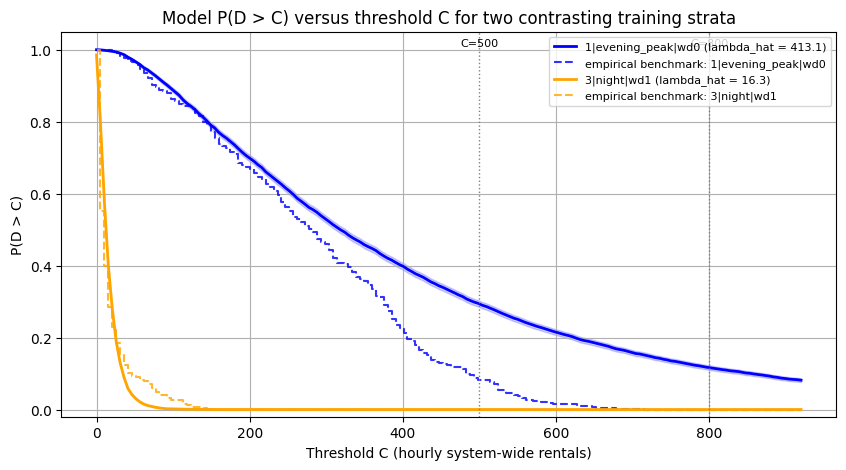

INTERPRETATION (RQ4):
At the fixed absolute thresholds, model P(D>C) ranges from 0.000 to 0.293 across eligible strata, with a maximum Monte Carlo standard error of 0.0050.
The Monte Carlo standard error sqrt(p(1-p)/N) measures simulation randomness only; it does not include fitted-parameter uncertainty or uncertainty about whether the dataset represents future demand.
Absolute thresholds are comparable across strata because C is the same everywhere. Stratum-relative thresholds are not comparable across strata: each is a different absolute value, so comparing their probabilities compares relative positions, not absolute demand.
The empirical benchmark is close to the training quantiles by construction, especially for the relative thresholds; it validates the simulation code path and provides a descriptive reference, not evidence that the parametric model is correct.


In [18]:
# Step 17a: exceedance curves for the highest and lowest fitted intensity
hi_stratum = strata_table["lambda_hat"].idxmax()
lo_stratum = strata_table["lambda_hat"].idxmin()
cmax = max(absolute_thresholds[1], float(strata_table.loc[hi_stratum, "q99"]),
           float(strata_table.loc[lo_stratum, "q99"]))
grid = np.linspace(0, cmax * 1.15, 180)

plt.figure(figsize=(10, 5))
for stratum, color in [(hi_stratum, "blue"), (lo_stratum, "orange")]:
    draws = draws_all[stratum]
    p_mc = np.array([np.mean(draws > c) for c in grid])
    se = np.sqrt(p_mc * (1 - p_mc) / n_mc)
    plt.plot(grid, p_mc, color=color, linewidth=2,
             label=f"{stratum} (lambda_hat = {strata_table.loc[stratum, 'lambda_hat']:.1f})")
    plt.fill_between(grid, np.maximum(0, p_mc - 1.96 * se), np.minimum(1, p_mc + 1.96 * se),
                     color=color, alpha=0.18)
    emp_curve = np.array([np.mean(emp_draws[stratum] > c) for c in grid])
    plt.step(grid, emp_curve, where="post", color=color, linestyle="--", alpha=0.8,
             label=f"empirical benchmark: {stratum}")
for C in absolute_thresholds:
    plt.axvline(C, color="grey", linestyle=":", linewidth=1)
    plt.text(C, 1.01, f"C={C}", rotation=0, ha="center", fontsize=8)
plt.title("Model P(D > C) versus threshold C for two contrasting training strata")
plt.xlabel("Threshold C (hourly system-wide rentals)")
plt.ylabel("P(D > C)")
plt.ylim(-0.02, 1.05)
plt.legend(fontsize=8, loc="upper right")
plt.grid(True)
plt.show()

# Step 17b: interpretation
print("INTERPRETATION (RQ4):")
p_abs = mc_table[mc_table["kind"] == "absolute"]
print(f"At the fixed absolute thresholds, model P(D>C) ranges from {p_abs['model_p_mc'].min():.3f} to "
      f"{p_abs['model_p_mc'].max():.3f} across eligible strata, with a maximum Monte Carlo standard error "
      f"of {mc_table['mc_se'].max():.4f}.")
print("The Monte Carlo standard error sqrt(p(1-p)/N) measures simulation randomness only; it does not "
      "include fitted-parameter uncertainty or uncertainty about whether the dataset represents future demand.")
print("Absolute thresholds are comparable across strata because C is the same everywhere. Stratum-relative "
      "thresholds are not comparable across strata: each is a different absolute value, so comparing their "
      "probabilities compares relative positions, not absolute demand.")
print("The empirical benchmark is close to the training quantiles by construction, especially for the "
      "relative thresholds; it validates the simulation code path and provides a descriptive reference, not "
      "evidence that the parametric model is correct.")

## Step 18: Validate on the chronological holdout

**Research question.** On data the model never saw, how well does the selected model's full predictive distribution reproduce stratum-level exceedance probabilities?

Training-derived thresholds are applied unchanged. Cells below the minimum held-out size are pooled by first dropping the hour bin within the same weather and working-day group, and then, only if still too small, by pooling weather. Pooling is probability-weighted at the observation level. A zero observed frequency is reported as zero with a one-sided upper confidence bound. A model probability of exactly zero with an observed exceedance is flagged as a calibration failure.

In [19]:
source_banner()
print(f"Selected model: {selected_key}")
print(f"Held-out evaluation rows: {len(eval_data):,} "
      f"({eval_data.dteday.min().date()} to {eval_data.dteday.max().date()})")
print("Pooling formulas: pooled observed p = total exceedances / total n_test; pooled model p = "
      "sum_i P_i(D > C_i) / n_test. Observations keep their own training-derived C_i when a pooled cell "
      "mixes hour bins.")

eval_data = eval_data.copy()
eval_data["lam_sel"] = selected_lam_heldout
val_rng = np.random.default_rng(31415)


def clopper_pearson_upper(k, n, level=1 - alpha):
    # One-sided upper bound for a binomial proportion; used when k == 0.
    if n <= 0:
        return np.nan
    return float(stats.beta.ppf(level, k + 1, n - k))


def summarize_cell(g, label, pooling_rule, c_repr):
    n_cell = len(g)
    k_cell = int(g["ind"].sum())
    obs = k_cell / n_cell
    pred = float(g["p"].mean())
    brier = float(np.mean((g["ind"] - g["p"]) ** 2))

    idx = val_rng.integers(0, n_cell, size=n_mc)
    lam_draw = g["lam_sel"].to_numpy()[idx]
    c_draw = g["C"].to_numpy()[idx]
    if selected_alpha is None:
        sim = val_rng.poisson(lam_draw)
    else:
        shape = 1.0 / float(selected_alpha)
        sim = stats.nbinom.rvs(shape, shape / (shape + lam_draw), size=n_mc, random_state=val_rng)
    sim_ind = sim > c_draw
    mc_p = float(sim_ind.mean())
    mc_se = float(sim_ind.std(ddof=1) / np.sqrt(n_mc))

    upper = clopper_pearson_upper(k_cell, n_cell) if k_cell == 0 else np.nan
    se_obs = np.sqrt(obs * (1 - obs) / n_cell)
    tolerance = 1.96 * np.sqrt(se_obs ** 2 + mc_se ** 2)
    within_noise = bool(abs(pred - obs) <= tolerance)
    zero_fail = bool(((g["p"].to_numpy() == 0) & (g["ind"].to_numpy() == 1)).any()
                     or (pred == 0 and k_cell > 0))

    return {
        "stratum": label,
        "pooling_rule": pooling_rule,
        "C": c_repr,
        "n_test": n_cell,
        "exceedances": k_cell,
        "observed_p": obs,
        "upper_if_zero": upper,
        "model_p": pred,
        "mc_se": mc_se,
        "gap": pred - obs,
        "brier": brier,
        "within_noise": within_noise,
        "flag": "CALIBRATION FAILURE: zero predicted, exceedance observed" if zero_fail else "",
    }


# Step 18a: per-threshold validation tables with explicit pooling rules
validation_tables = {}
val_summary_rows = []
for tname, kind, value in threshold_defs:
    C = threshold_vector(kind, value, eval_data)
    p = survival_from_lam(selected_model, selected_lam_heldout, C)
    ind = (eval_data["cnt"].to_numpy() > C).astype(int)
    tmp = eval_data.assign(C=C, p=p, ind=ind)

    sizes = tmp.groupby("stratum").size()
    small = set(sizes[sizes < min_cell_test].index)
    rows = []

    for stratum in sizes.index:
        if stratum not in small:
            g = tmp[tmp["stratum"] == stratum]
            c_repr = f"{float(g['C'].iloc[0]):.1f}"
            rows.append(summarize_cell(g, stratum, "none", c_repr))

    if small:
        sm = tmp[tmp["stratum"].isin(small)]
        leftover = []
        for (w, wd), g in sm.groupby(["weather_merged", "workingday"]):
            if len(g) >= min_cell_test:
                label = " + ".join(sorted(g["stratum"].unique()))
                rule = f"hour_bin dropped within weather={int(w)}, workingday={int(wd)}"
                rows.append(summarize_cell(g, label, rule, "cell-specific"))
            else:
                leftover.append(g)
        if leftover:
            g = pd.concat(leftover)
            label = " + ".join(sorted(g["stratum"].unique()))
            if len(g) >= min_cell_test:
                rows.append(summarize_cell(g, label, "hour_bin and weather pooled", "cell-specific"))
            else:
                rows.append({
                    "stratum": label, "pooling_rule": "insufficient data after pooling",
                    "C": "cell-specific", "n_test": len(g), "exceedances": int(g["ind"].sum()),
                    "observed_p": np.nan, "upper_if_zero": np.nan, "model_p": np.nan,
                    "mc_se": np.nan, "gap": np.nan, "brier": np.nan,
                    "within_noise": False, "flag": "NA: n_test < minimum after pooling",
                })

    val = pd.DataFrame(rows)
    val["is_pooled"] = val["pooling_rule"] != "none"
    val = val.sort_values(["is_pooled", "stratum"]).drop(columns="is_pooled").reset_index(drop=True)
    validation_tables[tname] = val

    n_total = int(val["n_test"].sum())
    k_total = int(val["exceedances"].sum())
    obs_total = k_total / n_total if n_total else np.nan
    pred_total = float((val["model_p"] * val["n_test"]).sum() / n_total) if n_total else np.nan
    brier_total = float((val["brier"] * val["n_test"]).sum() / n_total) if n_total else np.nan
    val_summary_rows.append({
        "threshold": tname,
        "kind": kind,
        "n_test": n_total,
        "exceedances": k_total,
        "observed_p": obs_total,
        "model_p": pred_total,
        "gap": pred_total - obs_total,
        "brier": brier_total,
        "cells": len(val),
        "zero_pred_failures": int(val["flag"].str.contains("CALIBRATION FAILURE").sum()),
        "within_noise_cells": int(val["within_noise"].sum()),
        "large_gap_cells": int((val["gap"].abs() > 0.10).sum()),
    })

    print(f"\nValidation threshold: {tname} ({kind})")
    print("Pooling rule is printed for every cell; original stratum labels are retained.")
    print(val[["stratum", "pooling_rule", "C", "n_test", "exceedances", "observed_p",
               "upper_if_zero", "model_p", "mc_se", "gap", "brier", "flag"]].round(4).to_string())

# Step 18b: validation summary and the largest gaps
validation_summary = pd.DataFrame(val_summary_rows)
print("\nVALIDATION SUMMARY")
print(validation_summary.round(4).to_string())
print("A zero observed frequency is a legitimate result and is shown with a one-sided upper bound. Cells "
      "are marked NA only when the held-out size is below the minimum after pooling.")

all_val = pd.concat([v.assign(threshold=t) for t, v in validation_tables.items()], ignore_index=True)
worst = (all_val.dropna(subset=["gap"])
         .assign(abs_gap=lambda d: d["gap"].abs())
         .sort_values("abs_gap", ascending=False)
         .head(8))
print("\nLargest held-out calibration gaps (absolute value):")
print(worst[["threshold", "stratum", "C", "n_test", "exceedances", "observed_p",
             "model_p", "gap", "brier", "flag"]].round(4).to_string())

Selected model: NB2 (drift-aware)
Held-out evaluation rows: 3,389 (2012-08-08 to 2012-12-31)
Pooling formulas: pooled observed p = total exceedances / total n_test; pooled model p = sum_i P_i(D > C_i) / n_test. Observations keep their own training-derived C_i when a pooled cell mixes hour bins.

Validation threshold: abs_500 (absolute)
Pooling rule is printed for every cell; original stratum labels are retained.
                                    stratum                                     pooling_rule              C  n_test  exceedances  observed_p  upper_if_zero  model_p   mc_se     gap   brier flag
0                        1|evening_peak|wd0                                             none          500.0      89           22      0.2472            NaN   0.5464  0.0050  0.2992  0.2490     
1                        1|evening_peak|wd1                                             none          500.0     191          150      0.7853            NaN   0.5471  0.0050 -0.2382  0.1956     
2 


Validation threshold: abs_800 (absolute)
Pooling rule is printed for every cell; original stratum labels are retained.
                                    stratum                                     pooling_rule              C  n_test  exceedances  observed_p  upper_if_zero  model_p   mc_se     gap   brier flag
0                        1|evening_peak|wd0                                             none          800.0      89            0      0.0000         0.0331   0.2994  0.0046  0.2994  0.1020     
1                        1|evening_peak|wd1                                             none          800.0     191           67      0.3508            NaN   0.2927  0.0046 -0.0581  0.1990     
2                                1|late|wd0                                             none          800.0     112            0      0.0000         0.0264   0.0163  0.0013  0.0163  0.0004     
3                                1|late|wd1                                             none          80


Validation threshold: q95 (relative)
Pooling rule is printed for every cell; original stratum labels are retained.
                                    stratum                                     pooling_rule              C  n_test  exceedances  observed_p  upper_if_zero  model_p   mc_se     gap   brier flag
0                        1|evening_peak|wd0                                             none          530.5      89           17      0.1910            NaN   0.5165  0.0050  0.3255  0.2394     
1                        1|evening_peak|wd1                                             none          811.8     191           61      0.3194            NaN   0.2856  0.0045 -0.0338  0.1893     
2                                1|late|wd0                                             none          300.5     112            7      0.0625            NaN   0.3191  0.0047  0.2566  0.1252     
3                                1|late|wd1                                             none          359.3 

## Step 19: Interpret the validation results

In [20]:
# Step 19: reading the validation tables honestly
print("INTERPRETATION (VALIDATION):")
for tname in ["abs_500", "abs_800", "q90", "q99"]:
    row = validation_summary[validation_summary["threshold"] == tname].iloc[0]
    print(f"At {tname}: observed {row['observed_p']:.3f}, model {row['model_p']:.3f}, "
          f"gap {row['gap']:+.3f}, Brier {row['brier']:.4f}, "
          f"cells within combined noise {int(row['within_noise_cells'])}/{int(row['cells'])}.")
n_zero_fail = int(validation_summary["zero_pred_failures"].sum())
print(f"Calibration failures with a zero model probability and a realized exceedance: {n_zero_fail}.")
month_gap = diag_month["fitted_mean"] - diag_month["observed_mean"]
print(f"Held-out monthly fitted-minus-observed mean count ranges from {month_gap.min():+.1f} to "
      f"{month_gap.max():+.1f}; the drift-aware model still misses part of the late-period level.")
print(f"The count diagnostic points to a specification problem, not simulation noise: the additive model "
      f"overpredicts {wh_label(wh_gap.idxmax())} by {wh_gap.max():+.1f} rentals per hour and underpredicts "
      f"{wh_label(wh_gap.idxmin())} by {wh_gap.min():+.1f}. The additive working-day and hour-bin terms "
      "cannot represent their interaction, so several validation cells fail even when the overall mean is close.")
print("The model matches reasonably in some cells and fails in others; the failures are concentrated where "
      "the additive structure, temporal drift, within-stratum date variation, and rare tail events are strongest.")
print("The drift-aware specification reduces the time-free model's systematic underprediction, but it does "
      "not eliminate drift: its year step and month effects can overpredict the rarer held-out tail. The "
      "correct conclusion is that the parametric model is trusted only where validation passes; elsewhere it "
      "is descriptive.")
print("Empirical resampling remains a benchmark, not proof of parametric accuracy. It validates trivially by "
      "construction and cannot fail on the training distribution; only the chronological holdout can expose "
      "the parametric model's errors.")

INTERPRETATION (VALIDATION):
At abs_500: observed 0.142, model 0.182, gap +0.040, Brier 0.0867, cells within combined noise 4/24.
At abs_800: observed 0.027, model 0.068, gap +0.041, Brier 0.0237, cells within combined noise 3/24.
At q90: observed 0.268, model 0.318, gap +0.050, Brier 0.1982, cells within combined noise 10/24.
At q99: observed 0.068, model 0.162, gap +0.094, Brier 0.0869, cells within combined noise 7/24.
Calibration failures with a zero model probability and a realized exceedance: 0.
Held-out monthly fitted-minus-observed mean count ranges from +13.9 to +48.3; the drift-aware model still misses part of the late-period level.
The count diagnostic points to a specification problem, not simulation noise: the additive model overpredicts workingday=0, evening_peak by +293.6 rentals per hour and underpredicts workingday=0, midday by -72.4. The additive working-day and hour-bin terms cannot represent their interaction, so several validation cells fail even when the overall m

## Step 20: Assumptions, limitations, and threats to validity

- **`cnt` is system-wide hourly rentals, not station inventory.** The analysis says nothing about station capacity, docking availability, shortages, or unmet demand. The thresholds are hypothetical demand levels chosen for the probability question.
- **Thresholds are descriptive devices.** The absolute values are fixed constants, and the stratum-relative values are training quantiles. Neither is an operational definition of an extreme event. Stratum-relative thresholds are not comparable across strata because each is a different absolute value.
- **Overdispersion and zero-inflation risk.** The data are overdispersed relative to Poisson even after the covariates; NB2 is used, but it is not guaranteed to capture every tail feature. Rare very-high-demand hours can produce calibration failures.
- **Autocorrelation.** Hourly rows share weather, date, and time-of-day effects; hourly tests would be invalid. The t-test uses daily totals, and the block bootstrap addresses remaining day-to-day dependence. The count model's independence assumptions are still approximate.
- **Temporal drift.** Demand grows across the study period. A chronological holdout is harder than a random split and deliberately exposes this. The drift-aware model uses a year step and month effects, which cannot represent continuous growth or unusual late-period events.
- **Weather merging.** The smallest weather category is merged into the adjacent adverse category before splitting. This is a deterministic recode, but it changes the interpretation of the weather coefficients and the strata.
- **Monte Carlo standard error.** The reported `sqrt(p(1-p)/N)` measures simulation randomness only. It does not include uncertainty in the fitted coefficients, uncertainty in the dispersion parameter, or uncertainty about whether the historical dataset represents future demand.
- **Boundary problem in the LR test.** The Poisson-versus-NB test places the null on the boundary of the parameter space, so the naive chi-square p-value is halved. The LR statistic is still a useful diagnostic.
- **The above-median label and the chi-square test.** The median is estimated from the same data, and the binary label discards information. The chi-square result is an association, not a causal effect.
- **Synthetic fallback.** If the download fails, the notebook runs on labelled synthetic data and must not be used for submitted findings. The `DATA_SOURCE` label is printed in the first cell and in the final conclusion.

## Step 21: Reproducibility checklist and final conclusion

**Run instructions.** Open the notebook in Google Colab and choose *Run all*. The Step 1 code downloads the UCI archive and extracts `hour.csv`; no manual upload is required. If the download fails, the notebook prints a prominent synthetic-data warning and continues.

**What to check after running.**

- `DATA_SOURCE` is printed as `uci`.
- Step 3 prints non-overlapping date ranges and row counts.
- Step 4 prints the shape statistics; Step 5 draws the density histogram with the normal and Poisson overlays plus both Q-Q panels, and no normality assumption is made.
- Steps 7 to 9 print the Welch test, the pooled-variance sensitivity check, the confidence interval, Cohen's d, and the block-bootstrap check.
- Steps 11 and 12 print the chi-square statistic, degrees of freedom, minimum expected frequency, and Cramér's V.
- Step 13 prints AIC, dispersion diagnostics, and the boundary-corrected LR result.
- Step 14 prints held-out NLL, deviance, per-cell calibration, Brier scores, and the selection ranking.
- Step 16 prints Monte Carlo probabilities with standard errors for absolute and relative thresholds.
- Step 18 prints the per-cell table, the pooling rule that fired, zero-frequency upper bounds, and failure flags.
- Step 21 prints the `DATA_SOURCE` label and the filled conclusion.

All numeric values are computed at runtime; none are hard-coded in this Markdown.

In [21]:
source_banner()

# Step 21a: reproducibility checklist
print(f"DATA_SOURCE: {data_source}")
print(f"Rows: {len(data):,}")
print(f"Distinct dates: {data.dteday.nunique():,}")
print(f"Date range: {data.dteday.min().date()} to {data.dteday.max().date()}")
print(f"Training rows: {len(train_data):,}")
print(f"Held-out rows: {len(test_data):,}")
print(f"Common held-out evaluation rows: {len(eval_data):,}")
print(f"Selected model: {selected_key}")
print(f"Eligible training strata: {len(eligible)}")
print(f"Monte Carlo draws: {n_mc:,}")
print(f"Absolute thresholds: {absolute_thresholds}")
print(f"Relative quantiles: {relative_quantiles}")
print(f"RQ1 diagnostic p-value (raw cnt): {fmt_p(dago_raw.pvalue)}")
print(f"RQ2 Welch p-value: {fmt_p(welch.pvalue)}")
print(f"RQ2 difference: {diff:,.2f}")
print(f"RQ2 95% CI: [{ci_low:,.2f}, {ci_high:,.2f}]")
print(f"RQ2 Cohen's d: {cohen_d:.3f}")
print(f"RQ3 chi-square: {chi2:.3f}")
print(f"RQ3 p-value: {fmt_p(p_chi)}")
print(f"RQ3 degrees of freedom: {dof}")
print(f"RQ3 minimum expected frequency: {min_expected:.2f}")
print(f"RQ3 Cramer's V: {cramers_v:.4f}")
print(f"Zero-predicted calibration failures in validation: {int(validation_summary['zero_pred_failures'].sum())}")

# Step 21b: final conclusion
template = ("Under specified weather and calendar conditions, the fitted model estimates the probability "
            "that hourly system-wide rentals exceed a chosen demand threshold.")
filled = (f"Data source = {data_source}; selected model = {selected_key}. " + template +
          " This is a system-wide demand threshold exceedance probability, not station capacity, station "
          "inventory, or actual unmet demand; the thresholds are hypothetical and the validation table "
          "shows where the model is and is not trusted.")
print("\nFINAL-CONCLUSION TEMPLATE:")
print(template)
print("\nFILLED CONCLUSION:")
print(filled)
if data_source == "synthetic":
    print("\nWARNING: this conclusion was produced with SYNTHETIC FALLBACK data and is not a real finding.")
print(f"\nElapsed wall-clock time: {time.time() - start_time:.1f} seconds")

DATA_SOURCE: uci
Rows: 17,379
Distinct dates: 731
Date range: 2011-01-01 to 2012-12-31
Training rows: 13,915
Held-out rows: 3,464
Common held-out evaluation rows: 3,389
Selected model: NB2 (drift-aware)
Eligible training strata: 25
Monte Carlo draws: 10,000
Absolute thresholds: (500, 800)
Relative quantiles: (90, 95, 99)
RQ1 diagnostic p-value (raw cnt): < 1e-300
RQ2 Welch p-value: 0.1101
RQ2 difference: 254.65
RQ2 95% CI: [-57.94, 567.24]
RQ2 Cohen's d: 0.132
RQ3 chi-square: 374.402
RQ3 p-value: 5.008e-82
RQ3 degrees of freedom: 2
RQ3 minimum expected frequency: 709.49
RQ3 Cramer's V: 0.1468
Zero-predicted calibration failures in validation: 0

FINAL-CONCLUSION TEMPLATE:
Under specified weather and calendar conditions, the fitted model estimates the probability that hourly system-wide rentals exceed a chosen demand threshold.

FILLED CONCLUSION:
Data source = uci; selected model = NB2 (drift-aware). Under specified weather and calendar conditions, the fitted model estimates the probab